<a href="https://colab.research.google.com/github/Lyra0710/Multimodal-Deep-Learning-for-Reliable-GRACE-Water-Storage-Trends/blob/main/notebooks/GRACE_GRACE_FO_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# This notebook downloads the NASA source to the selected storage location.
# Google Colab installs its downloader automatically; local environments install it separately.

In [2]:
import importlib.util
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None

if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "podaac-data-subscriber", "netCDF4", "python-dotenv", "PyYAML",
    ])
else:
    print("Not running in Google Colab; dependency installation skipped.")

Not running in Google Colab; dependency installation skipped.


In [3]:
from pathlib import Path
import os
import shutil
import subprocess
import sys
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt


In [4]:
# Choose where raw and processed data live: "github" or "drive".
# GitHub mode uses <repository>/data/raw and <repository>/data/processed.
# Drive mode prompts for the Drive project folder that contains data/.
STORAGE = "github"

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "scripts" / "grace_fo_processing.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find the repository root. Run the notebook from a clone of the repository."
    )

PROJECT_ROOT = find_project_root(Path.cwd().resolve())

if STORAGE == "github":
    STORAGE_ROOT = PROJECT_ROOT
elif STORAGE == "drive":
    from google.colab import drive

    DRIVE_MOUNT = Path(input("Google Drive mount point: " )).expanduser()
    drive.mount(str(DRIVE_MOUNT))
    STORAGE_ROOT = Path(
        input("Google Drive project folder (the folder containing data/): " )
    ).expanduser()
else:
    raise ValueError("STORAGE must be 'github' or 'drive'")

RAW_DIR = STORAGE_ROOT / "data" / "raw"
PROCESSED_DIR = STORAGE_ROOT / "data" / "processed"
PROCESSING_SCRIPT = PROJECT_ROOT / "scripts" / "grace_fo_processing.py"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


In [5]:
print("Storage:", STORAGE)
print("Raw data:", RAW_DIR)
print("Processed data:", PROCESSED_DIR)
print("Processing script:", PROCESSING_SCRIPT)

Storage: github
Raw data: /Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/data/raw
Processed data: /Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/data/processed
Processing script: /Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/scripts/grace_fo_processing.py


In [6]:
from dotenv import load_dotenv

env_path = PROJECT_ROOT / ".env"
if not env_path.is_file():
    raise FileNotFoundError(
        f"Missing {env_path}. Copy .env.example to .env and add your Earthdata credentials."
    )

load_dotenv(env_path)
username = os.getenv("EARTHDATA_USERNAME")
password = os.getenv("EARTHDATA_PASSWORD")
if not username or not password:
    raise RuntimeError(
        "Set EARTHDATA_USERNAME and EARTHDATA_PASSWORD in .env before downloading."
    )

netrc_path = Path.home() / ".netrc"

netrc_path.write_text(
    f"machine urs.earthdata.nasa.gov\n"
    f"login {username}\n"
    f"password {password}\n"
)

netrc_path.chmod(0o600)

del username, password
print("Earthdata credentials configured from .env.")

Earthdata credentials configured from .env.


In [7]:
downloader = shutil.which("podaac-data-downloader")
if downloader is None:
    raise RuntimeError(
        "podaac-data-downloader is not installed. In your active local environment, run: "
        "python -m pip install podaac-data-subscriber"
    )

subprocess.run([
    downloader,
    "-c", "TELLUS_GRAC-GRFO_MASCON_CRI_GRID_RL06.3_V4",
    "-d", str(RAW_DIR),
    "--start-date", "2019-01-01T00:00:00Z",
    "--end-date", "2025-12-31T23:59:59Z",
    "-e", ".nc",
], check=True)

[2026-10-25 01:43:46,489] {podaac_data_downloader.py:317} INFO - Found 1 total files to download
[2026-10-25 01:43:46,609] {podaac_data_downloader.py:350} INFO - 2026-10-25 01:43:46.609699 SKIPPED: https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/TELLUS_GRAC-GRFO_MASCON_CRI_GRID_RL06.3_V4/GRCTellus.JPL.200204_202607.GLO.RL06.3M.MSCNv04CRI.nc
[2026-10-25 01:43:46,609] {podaac_data_downloader.py:369} INFO - Downloaded Files: 0
[2026-10-25 01:43:46,609] {podaac_data_downloader.py:370} INFO - Failed Files:     0
[2026-10-25 01:43:46,609] {podaac_data_downloader.py:371} INFO - Skipped Files:    1
[2026-10-25 01:43:46,609] {podaac_data_downloader.py:177} INFO - Success Count: 0
[2026-10-25 01:43:46,609] {podaac_data_downloader.py:186} INFO - END




CompletedProcess(args=['/Users/annie/.pyenv/versions/3.11.9/bin/podaac-data-downloader', '-c', 'TELLUS_GRAC-GRFO_MASCON_CRI_GRID_RL06.3_V4', '-d', '/Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/data/raw', '--start-date', '2019-01-01T00:00:00Z', '--end-date', '2025-12-31T23:59:59Z', '-e', '.nc'], returncode=0)

In [8]:
files = sorted(RAW_DIR.glob("*.nc"))

for file in files:
    print(file.name, f"{file.stat().st_size / 1e6:.2f} MB")

print("Total files:", len(files))

if len(files) != 1:
    raise RuntimeError(f"Expected exactly one raw NetCDF file in {RAW_DIR}, found {len(files)}")

RAW_FILE = files[0]
PROCESSED_FILE = PROCESSED_DIR / "grace_fo_processed.nc"
print("Raw input:", RAW_FILE)
print("Processed output:", PROCESSED_FILE)

GRCTellus.JPL.200204_202607.GLO.RL06.3M.MSCNv04CRI.nc 45.99 MB
Total files: 1
Raw input: /Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/data/raw/GRCTellus.JPL.200204_202607.GLO.RL06.3M.MSCNv04CRI.nc
Processed output: /Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/data/processed/GRCTellus.JPL.200204_202607.GLO.RL06.3M.MSCNv04CRI_model_ready.nc


## Preprocess a separate, model-ready copy

The command passes explicit `--input` and `--output` locations to `grace_fo_processing.py`. It reads the NASA file from `data/raw/` and writes a new file to `data/processed/`; the original is never changed.

In [9]:
command = [
    sys.executable,
    str(PROCESSING_SCRIPT),
    "--input", str(RAW_FILE),
    "--output", str(PROCESSED_FILE),
    "--start", "2019-01-01",
    "--end", "2025-12-31",
]
print("Running:", " ".join(command))
subprocess.run(command, check=True)

# Analyze the new processed copy, not the original NASA NetCDF file.
grace = xr.open_dataset(PROCESSED_FILE)

print(grace)

Running: /opt/anaconda3/envs/266lab/bin/python /Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/scripts/grace_fo_processing.py --input /Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/data/raw/GRCTellus.JPL.200204_202607.GLO.RL06.3M.MSCNv04CRI.nc --output /Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/data/processed/GRCTellus.JPL.200204_202607.GLO.RL06.3M.MSCNv04CRI_model_ready.nc --start 2019-01-01 --end 2025-12-31
Validated: /Users/annie/Library/CloudStorage/OneDrive-Personal/Academics/Masters/SJSU/DATA-255/Group Project/data/processed/GRCTellus.JPL.200204_202607.GLO.RL06.3M.MSCNv04CRI_model_ready.nc
Months: 84 | Grid: 360 x 720
Variables: ['lwe_thickness', 'uncertainty', 'lat_bounds', 'lon_bounds', 'time_bounds', 'land_mask', 'scale_factor', 'mascon_ID', 'GAD', 'original_time']
File size: 34.3 MiB
<xarray.Dataset> Size: 529MB
Dimensions

In [10]:

expected = pd.period_range("2019-01", "2025-12", freq="M")
observed = pd.DatetimeIndex(grace.time.values).to_period("M")

missing = expected.difference(observed)

print("Expected months:", len(expected))
print("Available months:", len(observed))
print("Missing months:", len(missing))
print("Missing month list:", missing.astype(str).tolist())

Expected months: 84
Available months: 84
Missing months: 0
Missing month list: []


Inspecting the land mask

In [11]:


print("Land mask attributes:")
print(grace["land_mask"].attrs)

print("\nUnique land mask values:")
print(np.unique(grace["land_mask"].values))

Land mask attributes:
{'units': 'binary', 'long_name': 'Land_Mask', 'standard_name': 'Land_Mask', 'description': 'Land Mask that was used with the CRI filter'}

Unique land mask values:
[0. 1.]


## 1. Dataset Structure and Metadata

In [12]:
variable_info = []

for name, var in grace.data_vars.items():
    variable_info.append({
        "Variable": name,
        "Dimensions": str(var.dims),
        "Units": var.attrs.get("units", "Not specified"),
        "Description": var.attrs.get("long_name", "Not specified")
    })

display(pd.DataFrame(variable_info))

,Variable,Dimensions,Units,Description
0,lwe_thickness,"('time', 'lat', 'lon')",cm,Liquid_Water_Equivalent_Thickness
1,uncertainty,"('time', 'lat', 'lon')",cm,uncertainty
2,lat_bounds,"('lat', 'bounds')",Not specified,latitude boundaries
3,lon_bounds,"('lon', 'bounds')",Not specified,longitude boundaries
4,time_bounds,"('time', 'bounds')",Not specified,time boundaries
5,land_mask,"('lat', 'lon')",binary,Land_Mask
6,scale_factor,"('lat', 'lon')",dimensionless,Scale_Factor_CRI
7,mascon_ID,"('lat', 'lon')",dimensionless,Mascon_Identifier
8,GAD,"('time', 'lat', 'lon')",cm,OCEAN_ATMOSPHERE_DEALIAS_MODEL_(GAD)
9,original_time,"('time',)",Not specified,Not specified


In [13]:
# Inspect dataset metadata
for key, value in grace.attrs.items():
    print(f"{key}: {value}")

Conventions: CF-1.6, ACDD-1.3, ISO 8601
Metadata_Conventions: Unidata Dataset Discovery v1.0
standard_name_vocabulary: NetCDF Climate and Forecast (CF) Metadata Convention-1.6
title: JPL GRACE and GRACE-FO MASCON RL06.3Mv04 CRI
summary: Monthly gravity solutions from GRACE and GRACE-FO as determined from the JPL RL06.3Mv04 mascon solution - with CRI filter applied
keywords: Solid Earth, Geodetics/Gravity, Gravity, liquid_water_equivalent_thickness
keywords_vocabulary: NASA Global Change Master Directory (GCMD) Science Keywords
platform: GRACE and GRACE-FO
institution: NASA/JPL
creator_name: David Wiese
creator_email: grace@podaac.jpl.nasa.gov
creator_url: https://grace.jpl.nasa.gov
creator_type: group
creator_institution: NASA/JPL
publisher_name: Physical Oceanography Distributed Active Archive Center
publisher_email: podaac@jpl.nasa.gov
publisher_url: https://podaac.jpl.nasa.gov
publisher_type: group
publisher_institution: NASA/JPL
project: NASA Gravity Recovery and Climate Experiment

### Spatial and Temporal Coordinates

In [14]:
print("Time steps:", grace.sizes["time"])
print("Latitude points:", grace.sizes["lat"])
print("Longitude points:", grace.sizes["lon"])

print("\nLatitude range:",
      float(grace.lat.min().item()),
      float(grace.lat.max().item()))

print("Longitude range:",
      float(grace.lon.min().item()),
      float(grace.lon.max().item()))

print("\nFirst timestamp:", grace.time.values[0])
print("Last timestamp:", grace.time.values[-1])

print("\nLatitude spacing:",
      np.unique(np.round(np.diff(grace.lat.values), 5)))

print("Longitude spacing:",
      np.unique(np.round(np.diff(grace.lon.values), 5)))

Time steps: 84
Latitude points: 360
Longitude points: 720

Latitude range: -89.75 89.75
Longitude range: -179.75 179.75

First timestamp: 2019-01-01T00:00:00.000000000
Last timestamp: 2025-12-01T00:00:00.000000000

Latitude spacing: [0.5]
Longitude spacing: [0.5]


## 2. Data Integrity and Missing Values

In [15]:
quality = []

for name, var in grace.data_vars.items():
    if np.issubdtype(var.dtype, np.number):
        values = var.values

        quality.append({
            "Variable": name,
            "Total": values.size,
            "Missing (NaN)": np.isnan(values).sum(),
            "Infinite": np.isinf(values).sum(),
            "Valid": np.isfinite(values).sum()
        })

quality_df = pd.DataFrame(quality)

display(quality_df)

,Variable,Total,Missing (NaN),Infinite,Valid
0,lwe_thickness,21772800,0,0,21772800
1,uncertainty,21772800,0,0,21772800
2,lat_bounds,720,0,0,720
3,lon_bounds,1440,0,0,1440
4,land_mask,259200,0,0,259200
5,scale_factor,259200,200292,0,58908
6,mascon_ID,259200,0,0,259200
7,GAD,21772800,0,0,21772800


### Missing Values by Surface Type

In [16]:
twsa = grace["lwe_thickness"]
land = grace["land_mask"] == 1
ocean = grace["land_mask"] == 0

surface_quality = pd.DataFrame([
    {
        "Surface": "Land",
        "Grid cells": int(land.sum().item()),
        "Missing observations": int(
            (twsa.isnull() & land).sum().item()
        ),
        "Valid observations": int(
            (twsa.notnull() & land).sum().item()
        )
    },
    {
        "Surface": "Ocean",
        "Grid cells": int(ocean.sum().item()),
        "Missing observations": int(
            (twsa.isnull() & ocean).sum().item()
        ),
        "Valid observations": int(
            (twsa.notnull() & ocean).sum().item()
        )
    }
])

display(surface_quality)

,Surface,Grid cells,Missing observations,Valid observations
0,Land,85912,0,7216608
1,Ocean,173288,0,14556192


**`scale_factor` has missing values. Inspecting**

In [17]:
scale = grace["scale_factor"]

print("Scale factor metadata:")
print(scale.attrs)

print("\nScale factor availability:")

for name, mask in [("Land", land), ("Ocean", ocean)]:
    print(f"\n{name}:")
    print("Available:", int((scale.notnull() & mask).sum().item()))
    print("Missing:", int((scale.isnull() & mask).sum().item()))

Scale factor metadata:
{'units': 'dimensionless', 'long_name': 'Scale_Factor_CRI', 'standard_name': 'Scale_Factor_CRI', 'valid_min': np.float64(-2.8803287269599895), 'valid_max': np.float64(24.133988467789724), 'description': 'Gridded scale factors to be used with mascon solution that has the CRI filter applied; based on CLM data from 2002-2009'}

Scale factor availability:

Land:
Available: 58908
Missing: 27004

Ocean:
Available: 0
Missing: 173288


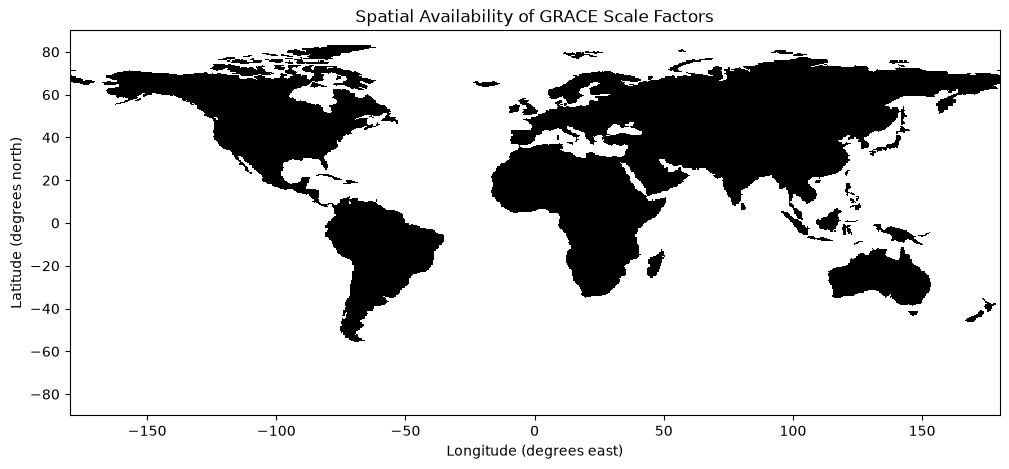

In [18]:
plt.figure(figsize=(12, 5))

scale.notnull().plot(
    cmap="Greys",
    add_colorbar=False
)

plt.title("Spatial Availability of GRACE Scale Factors")
plt.xlabel("Longitude (degrees east)")
plt.ylabel("Latitude (degrees north)")

plt.show()

This variable is a Candidate to exclude for modeling.

From the map, scale factors are available across much of the nonpolar land surface, but are absent over oceans and substantial polar areas.

## 3. Global TWSA (Terrestrial Water Storage Anomaly.) Map (January 2019)

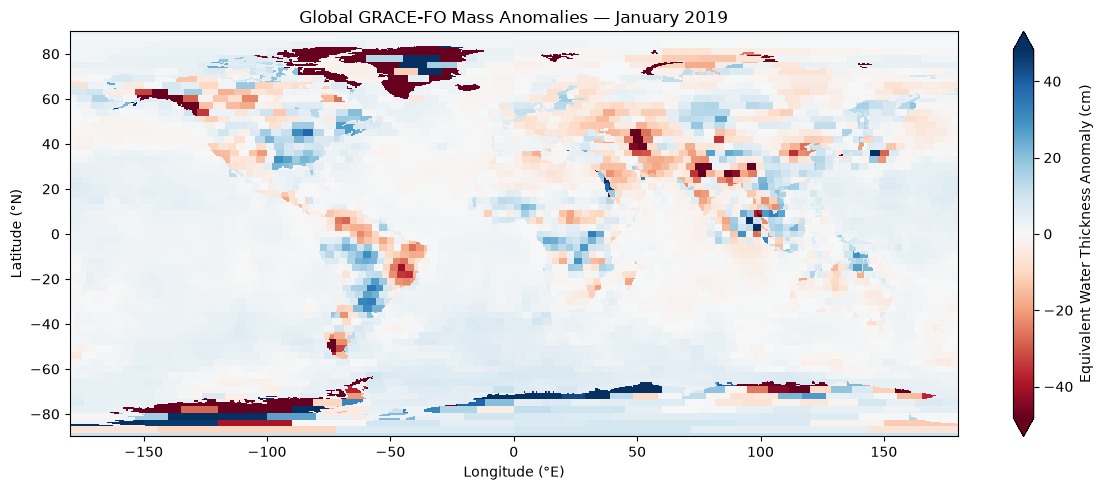

In [19]:
# Select January 2019
twsa_jan = grace["lwe_thickness"].sel(time="2019-01")

fig, ax = plt.subplots(figsize=(12, 5))

twsa_jan.plot(
    ax=ax,
    cmap="RdBu",
    center=0,
    robust=True,
    cbar_kwargs={
        "label": "Equivalent Water Thickness Anomaly (cm)"
    }
)

ax.set_title("Global GRACE-FO Mass Anomalies — January 2019")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

plt.tight_layout()
plt.show()

Summary Statistics

In [20]:
# January 2019 global mass anomalies
jan2019 = grace["lwe_thickness"].sel(time="2019-01")

# Calculate summary statistics
summary = pd.Series({
    "Minimum (cm)": float(jan2019.min()),
    "Maximum (cm)": float(jan2019.max()),
    "Mean (cm)": float(jan2019.mean()),
    "Median (cm)": float(jan2019.median()),
    "Standard deviation (cm)": float(jan2019.std()),
    "5th percentile (cm)": float(jan2019.quantile(0.05)),
    "95th percentile (cm)": float(jan2019.quantile(0.95))
})

display(summary.to_frame("Value").round(2))

,Value
Minimum (cm),-1301.79
Maximum (cm),783.03
Mean (cm),-1.90
Median (cm),1.77
Standard deviation (cm),39.96
5th percentile (cm),-13.01
95th percentile (cm),11.82


Land vs Ocean TWSA

In [21]:
land = grace["land_mask"] == 1
ocean = grace["land_mask"] == 0

results = []

for name, mask in [("Land", land), ("Ocean", ocean)]:
    values = jan2019.where(mask)

    results.append({
        "Surface": name,
        "Mean (cm)": float(values.mean()),
        "Median (cm)": float(values.median()),
        "Std (cm)": float(values.std()),
        "Min (cm)": float(values.min()),
        "Max (cm)": float(values.max())
    })

display(pd.DataFrame(results).round(2))

,Surface,Mean (cm),Median (cm),Std (cm),Min (cm),Max (cm)
0,Land,-9.80,0.08,68.53,-1301.79,783.03
1,Ocean,2.02,1.93,3.70,-97.15,78.52


Monthly Land TWSA Time Series

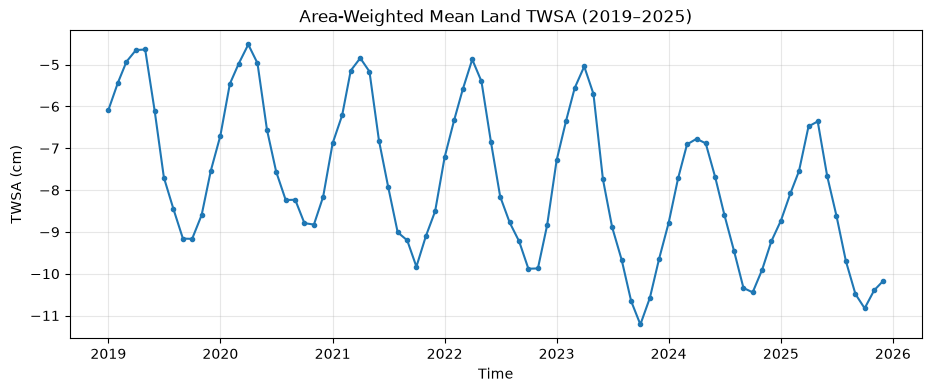

In [22]:
twsa_land = grace["lwe_thickness"].where(land)

# Weight grid cells by approximate geographic area
weights = np.cos(np.deg2rad(grace["lat"]))

monthly_mean = twsa_land.weighted(weights).mean(
    dim=["lat", "lon"]
)

plt.figure(figsize=(11, 4))

monthly_mean.plot(marker="o", markersize=3)

plt.title("Area-Weighted Mean Land TWSA (2019–2025)")
plt.xlabel("Time")
plt.ylabel("TWSA (cm)")
plt.grid(alpha=0.3)

plt.show()

A recurring annual pattern is visible.

Compare Polar and Nonpolar Land TWSA

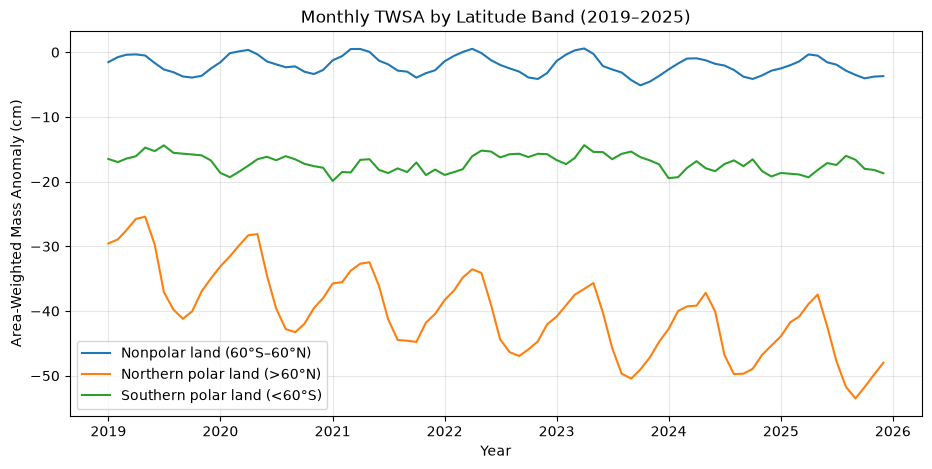

In [23]:
twsa = grace["lwe_thickness"]
land = grace["land_mask"] == 1

# Exploratory latitude bands (not ice-sheet classifications)
regions = {
    "Nonpolar land (60°S–60°N)": land & (abs(grace.lat) <= 60),
    "Northern polar land (>60°N)": land & (grace.lat > 60),
    "Southern polar land (<60°S)": land & (grace.lat < -60)
}

weights = np.cos(np.deg2rad(grace.lat))

plt.figure(figsize=(11, 5))

for name, mask in regions.items():
    series = twsa.where(mask).weighted(weights).mean(
        dim=["lat", "lon"]
    )
    series.plot(label=name)

plt.title("Monthly TWSA by Latitude Band (2019–2025)")
plt.xlabel("Year")
plt.ylabel("Area-Weighted Mass Anomaly (cm)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Check Temporal Autocorrelation

In [24]:
# Nonpolar land mean time series
nonpolar = regions["Nonpolar land (60°S–60°N)"]

series = twsa.where(nonpolar).weighted(weights).mean(
    dim=["lat", "lon"]
).to_pandas()

for lag in [1, 3, 6, 12]:
    print(f"Lag {lag} months: {series.autocorr(lag=lag):.3f}")

Lag 1 months: 0.853
Lag 3 months: 0.079
Lag 6 months: -0.805
Lag 12 months: 0.906


**Our data shows strong temporal structure and substantial geographic variation. This supports using historical TWSA and seasonality in our forecasting models.**

## 3. Variable Distributions

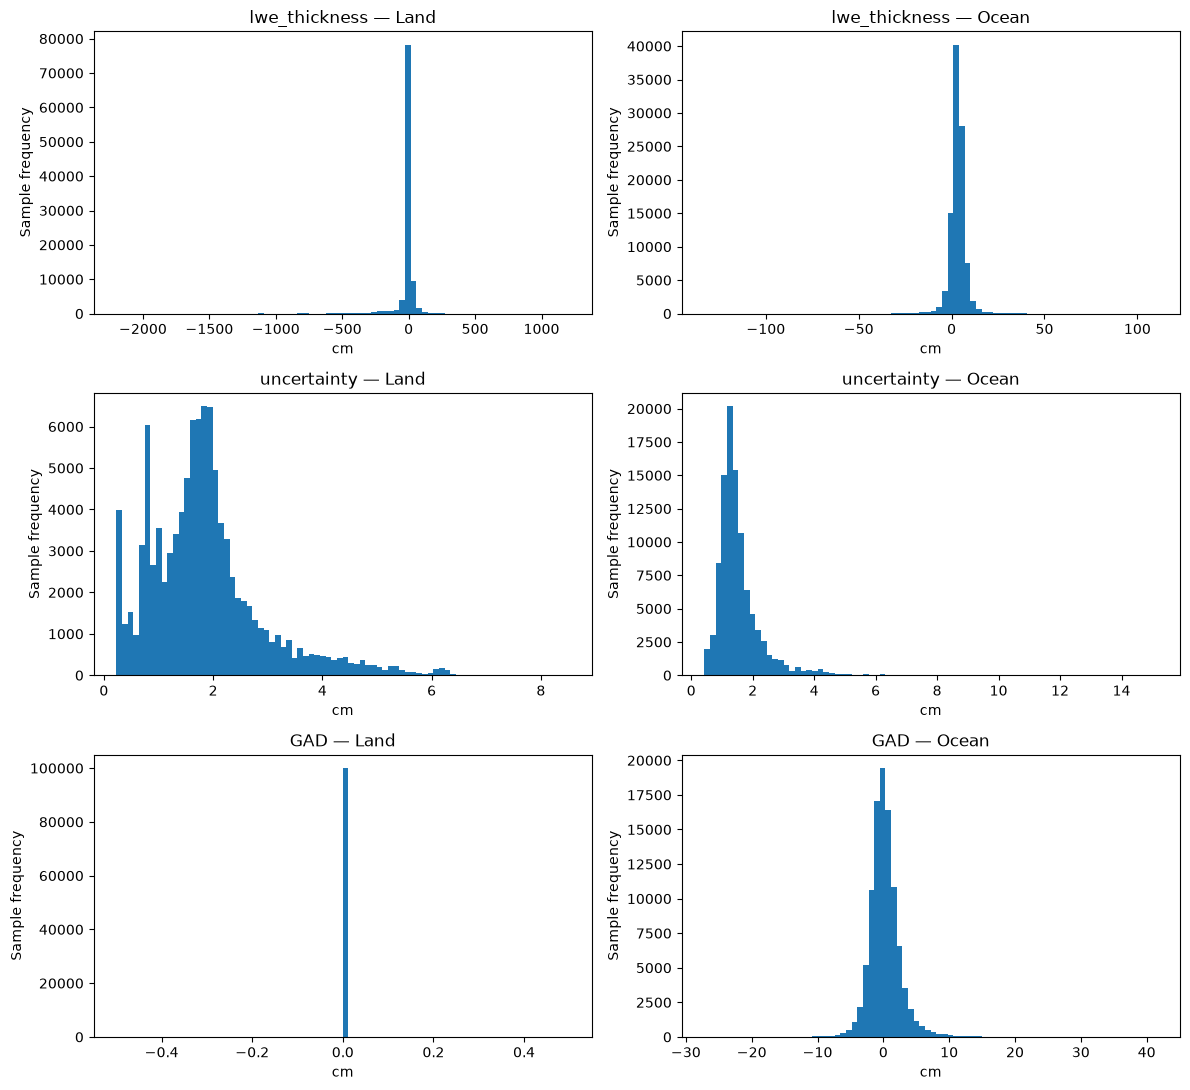

In [25]:
rng = np.random.default_rng(42)

variables = ["lwe_thickness", "uncertainty", "GAD"]
land_mask = grace["land_mask"].values == 1

fig, axes = plt.subplots(3, 2, figsize=(12, 11))

for i, name in enumerate(variables):
    data = grace[name].values

    for j, (label, mask) in enumerate([
        ("Land", land_mask),
        ("Ocean", ~land_mask)
    ]):
        values = data[:, mask].ravel()
        values = values[np.isfinite(values)]

        sample = rng.choice(
            values,
            size=min(100000, len(values)),
            replace=False
        )

        axes[i, j].hist(sample, bins=80)
        axes[i, j].set_title(f"{name} — {label}")
        axes[i, j].set_xlabel(grace[name].attrs.get("units", "Value"))
        axes[i, j].set_ylabel("Sample frequency")

plt.tight_layout()
plt.show()

In [26]:
measurements = ["lwe_thickness", "uncertainty", "GAD"]

land = grace["land_mask"].values == 1

rng = np.random.default_rng(42)
land_indices = np.flatnonzero(land.ravel())

# Sample spatial cells, retaining all their months
selected = rng.choice(
    land_indices,
    size=min(1000, len(land_indices)),
    replace=False
)

data = {}

for name in measurements:
    arr = grace[name].values.reshape(grace.sizes["time"], -1)
    data[name] = arr[:, selected].ravel()

df = pd.DataFrame(data)

correlations = df.corr(method="pearson")

display(correlations.round(3))

,lwe_thickness,uncertainty,GAD
lwe_thickness,1.000,-0.329,NaN
uncertainty,-0.329,1.000,NaN
GAD,NaN,NaN,NaN


Inspect Measurement Uncertainty

In [27]:
uncertainty = grace["uncertainty"]

results = []

for name, mask in [
    ("Land", grace["land_mask"] == 1),
    ("Ocean", grace["land_mask"] == 0)
]:
    values = uncertainty.where(mask)

    results.append({
        "Surface": name,
        "Mean (cm)": float(values.mean()),
        "Median (cm)": float(values.median()),
        "Std (cm)": float(values.std()),
        "Min (cm)": float(values.min()),
        "Max (cm)": float(values.max())
    })

display(pd.DataFrame(results).round(3))

,Surface,Mean (cm),Median (cm),Std (cm),Min (cm),Max (cm)
0,Land,1.849,1.736,1.054,0.227,8.623
1,Ocean,1.546,1.364,0.768,0.425,15.166


Verify GAD Values Over Land

In [28]:
# Check whether GAD is constant over land
gad_land = grace["GAD"].where(grace["land_mask"] == 1)

print("GAD minimum over land:", float(gad_land.min()))
print("GAD maximum over land:", float(gad_land.max()))

print("Nonzero land observations:",
      int(((gad_land != 0) & gad_land.notnull()).sum()))

GAD minimum over land: 0.0
GAD maximum over land: 0.0
Nonzero land observations: 0


Inspect Mascon Grouping

In [29]:
mascon_ids = grace["mascon_ID"].values

print("Unique mascon IDs:", len(np.unique(mascon_ids)))

land_ids = grace["mascon_ID"].where(
    grace["land_mask"] == 1
).values

print("Unique land mascon IDs:",
      len(np.unique(land_ids[np.isfinite(land_ids)])))

Unique mascon IDs: 4551
Unique land mascon IDs: 1706


# Insights and Observations

## 1. EDA Findings

- Data completeness: 84 consecutive monthly observations (2019–2025), with no missing TWSA values.
- Spatial coverage: 0.5° global grid containing 85,912 land cells and 173,288 ocean cells.
- Extreme values: Large anomalies occur near Greenland and Antarctica. No evidence that these are errors.
- Seasonality: Strong annual pattern (lag-12 autocorrelation = 0.906), suggesting seasonal features may be useful.
- Temporal dependence: High lag-1 autocorrelation (0.853), supporting a persistence baseline.
- Spatial dependence: 1,706 unique land mascon IDs; neighboring grid cells are not necessarily independent.
- Uncertainty: Available for all observations; important for later reliability analysis.
- GAD: Constant at zero over land, so not useful as an initial land-model predictor.
- Scale factor: Missing in some land areas; optional correction, not a standard predictive feature.

## 2. Features for Modeling

- Target: Next month's `lwe_thickness` (TWSA).
- Predictors: Historical TWSA, GPM precipitation, MERRA-2 temperature.
- Additional candidate: Month-of-year encoding to capture seasonality.
- Supporting variables: `uncertainty`, `land_mask`, `mascon_ID`, geographic coordinates.
- Exclude from initial predictors: `GAD` and `scale_factor`.

## 3. Data Preparation

- Keep January 2019–December 2025 observations.
- Standardize timestamps to the first day of each month.
- Convert longitude from 0–360° to −180–180°.
- Preserve GRACE's native 0.5° grid.
- Keep original TWSA values, extreme observations, and uncertainty.
- Preserve all NASA variables in the master dataset.
- Create a separate land-only modeling view.
- Do not normalize yet: Fit scaling parameters using training data only to prevent leakage.

## 4. Completed Baseline and Handoff

- The preprocessing script and chronological handoff splits have been completed.
- The deterministic one-month persistence baseline has been evaluated without changing the GRACE source or processed master dataset.
- Evaluation is restricted to `land_mask == 1` between 60°S and 60°N: 46,325 valid land cells.
- The shared target-month splits are train (2019–2022), validation (2023), and test (2024–2025).
- The primary reported RMSE is the cosine-latitude-weighted average of per-cell temporal RMSE values. The earlier pooled cell-month RMSE remains available separately for continuity.

## 5. Persistence Baseline Results

The next cell runs the persistence baseline, and the following cell displays its saved metrics. The test period has 24 target months, January 2024 through December 2025; the target-month coordinate runs from `2024-01-01` through `2025-12-01`.

In [30]:
PERSISTENCE_SCRIPT = PROJECT_ROOT / "scripts" / "grace_fo_persistence.py"
PERSISTENCE_CONFIG = PROJECT_ROOT / "configs" / "grace_fo_config.yaml"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
MODEL_OUTPUT = PROJECT_ROOT / "models" / "grace_fo_one_month_persistence_baseline.json"

command = [
    sys.executable, str(PERSISTENCE_SCRIPT),
    "--input", str(PROCESSED_FILE),
    "--config", str(PERSISTENCE_CONFIG),
    "--metrics-dir", str(METRICS_DIR),
    "--figures-dir", str(FIGURES_DIR),
    "--split-output-dir", str(PROCESSED_DIR),
    "--model-output", str(MODEL_OUTPUT),
]
print("Running:", " ".join(command))
subprocess.run(command, check=True)

Saved GRACE-FO persistence metrics: results/metrics/grace_fo_persistence_metrics.json
Saved GRACE-FO persistence model specification: models/grace_fo_one_month_persistence_baseline.json
Saved GRACE-FO chronological split manifest: results/metrics/grace_fo_chronological_splits.csv
train: MAE=3.436 cm | RMSE (area-weighted per-cell)=4.268 cm | pooled RMSE=5.770 cm | r=0.799 | months=47 | cells=46325
validation: MAE=3.364 cm | RMSE (area-weighted per-cell)=4.112 cm | pooled RMSE=5.598 cm | r=0.661 | months=12 | cells=46325
test: MAE=3.437 cm | RMSE (area-weighted per-cell)=4.201 cm | pooled RMSE=5.693 cm | r=0.764 | months=24 | cells=46325


In [31]:
import json

metrics_path = PROJECT_ROOT / "results" / "metrics" / "grace_fo_persistence_metrics.json"
with metrics_path.open() as stream:
    persistence_metrics = json.load(stream)

rows = []
for split, values in persistence_metrics["splits"].items():
    rows.append({
        "split": split,
        "target_start": values["target_start"],
        "target_end": values["target_end"],
        "evaluated_months": values["evaluated_months"],
        "evaluated_land_cells": values["evaluated_land_cells"],
        "MAE_cm": values["mae_cm"],
        "RMSE_per_cell_area_weighted_cm": values["area_weighted_per_cell_rmse_cm"],
        "pooled_RMSE_cm": values["pooled_rmse_cm"],
        "temporal_r": values["area_weighted_mean_temporal_pearson_r"],
    })

result_table = pd.DataFrame(rows).round(3)
print(result_table.to_string(index=False))
print("\nEvaluation domain: land_mask == 1 and -60 <= latitude <= 60.")
print("Primary RMSE: cosine-latitude area-weighted mean of per-cell temporal RMSE.")

     split target_start target_end  evaluated_months  evaluated_land_cells  MAE_cm  RMSE_per_cell_area_weighted_cm  pooled_RMSE_cm  temporal_r
     train   2019-01-01 2022-12-31                47                 46325   3.436                           4.268           5.770       0.799
validation   2023-01-01 2023-12-31                12                 46325   3.364                           4.112           5.598       0.661
      test   2024-01-01 2025-12-31                24                 46325   3.437                           4.201           5.693       0.764

Evaluation domain: land_mask == 1 and -60 <= latitude <= 60.
Primary RMSE: cosine-latitude area-weighted mean of per-cell temporal RMSE.
